# Praktikum Data Mining: Association Rule Mining (Market Basket Analysis)
## Notebook 1: Langkah-Langkah Praktikum (Bagian 4.1 sampai 4.8)
Nama: AUDITYA MEROSYA PUTRI | NIM: 24343001 

Nama: Muhammad Zahran       | NIM: 24343077

Nama: Muhammad Riyad Anwari | NIM: 24343044


In [7]:
# Instal mlxtend bila belum tersedia (di Google Colab: jalankan sel ini sekali)
try:
    import mlxtend
except ImportError:
    get_ipython().system('pip install mlxtend -q')
    import mlxtend
print('mlxtend versi', mlxtend.__version__)

mlxtend versi 0.25.0


**Analisis:**
Memeriksa ketersediaan library mlxtend yang diperlukan dalam proses analisis data menggunakan algoritma Apriori. Jika library belum tersedia, program akan menginstalnya secara otomatis menggunakan perintah pip install mlxtend.

## 4.1 Persiapan Data Transaksi
Data transaksi direpresentasikan sebagai *list of list*: tiap elemen adalah satu transaksi berisi daftar item yang dibeli. File CSV menyimpan item tiap transaksi dalam satu kolom `Items` (dipisah koma), sehingga perlu dipecah menjadi list.

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [[i.strip() for i in s.split(',')] for s in raw['Items']]

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


Sebelum memakai Apriori, periksa frekuensi kemunculan tiap item untuk mengenali item yang populer dan yang jarang dibeli. Informasi ini membantu memperkirakan nilai `min_support` yang wajar.

Susu        : 19  (support = 0.317)
Roti        : 18  (support = 0.300)
Mie Instan  : 18  (support = 0.300)
Mentega     : 17  (support = 0.283)
Telur       : 15  (support = 0.250)
Sabun       : 15  (support = 0.250)
Gula        : 14  (support = 0.233)
Kopi        : 13  (support = 0.217)
Shampo      : 13  (support = 0.217)
Kecap       : 12  (support = 0.200)
Keju        :  6  (support = 0.100)
Teh         :  4  (support = 0.067)


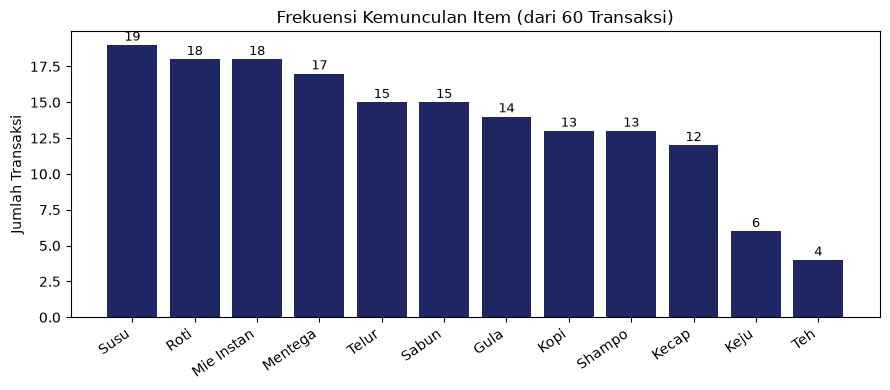

In [9]:
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:12s}: {freq:2d}  (support = {freq/len(transactions):.3f})')

item_urut = cnt.most_common()
plt.figure(figsize=(9, 4))
bars = plt.bar([i for i, _ in item_urut], [f for _, f in item_urut], color='#1E2761')
for b, (_, f) in zip(bars, item_urut):
    plt.text(b.get_x() + b.get_width() / 2, f + 0.3, str(f), ha='center', fontsize=9)
plt.xticks(rotation=35, ha='right'); plt.ylabel('Jumlah Transaksi')
plt.title('Frekuensi Kemunculan Item (dari 60 Transaksi)')
plt.tight_layout(); plt.savefig('arm_gambar2_frekuensi_item.png', dpi=150); plt.show()

**Pembacaan hasil:** Susu, Mie Instan, dan Roti adalah tiga item paling populer (support sekitar 0,30), sedangkan Teh dan Keju tergolong jarang (di bawah 0,10). Ambang `min_support` yang terlalu tinggi akan membuang semua item kecuali yang paling populer.

Support-nya diperoleh dengan membagi frekuensi dengan jumlah transaksi. Susu menjadi barang paling sering dibeli (19 transaksi, support 0,317), disusul Roti dan Mie Instan masing-masing 18 transaksi (0,300). Teh (4 transaksi) dan Keju (6 transaksi) adalah yang paling jarang. Diagram batang memperlihatkan perbedaan ini dan menjadi bahan pertimbangan dalam menentukan nilai min_support.

## 4.2 Encoding Data Transaksi ke Format One-Hot
`apriori()` dan `fpgrowth()` pada mlxtend membutuhkan matriks one-hot (satu kolom per item, nilai True/False), bukan list of list. `TransactionEncoder` melakukan konversi ini.

In [10]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

# Pemeriksaan: hasil encoding sama dengan file transactions_arm_praktikum_onehot.csv
try:
    onehot_csv = pd.read_csv('transactions_arm_praktikum_onehot.csv').astype(bool)
    sama = (onehot_csv[sorted(onehot_csv.columns)].values == df[sorted(df.columns)].values).all()
    print('\nSama dengan file one-hot yang disediakan?', bool(sama))
except FileNotFoundError:
    print('\n(file one-hot tidak ditemukan; pemeriksaan dilewati)')

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False

Sama dengan file one-hot yang disediakan? True


TransactionEncoder dipakai untuk mengubah data menjadi DataFrame berisi nilai True atau False, di mana True berarti barang tersebut ada pada transaksi yang bersangkutan. Matriks one-hot berukuran yang terbentuk adalah 60 baris dan 12 kolom. Hasil encoding juga dicocokkan dengan file one-hot bawaan praktikum dan hasilnya sama (True), sehingga proses konversi dapat dianggap benar.

## 4.3 Mencari Frequent Itemset dengan Algoritma Apriori
Dengan `min_support = 0.15` (setara minimal 9 dari 60 transaksi), Apriori mencari seluruh itemset yang sering muncul. Algoritma bekerja per level (1-itemset, 2-itemset, ...) dan memangkas kandidat memakai prinsip *downward closure*: jika suatu itemset tidak frequent, semua superset-nya pasti tidak frequent.

In [11]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.assign(itemsets=freq_apriori['itemsets'].map(lambda x: '(' + ', '.join(sorted(x)) + ')')).round(3).to_string(index=False))

ukuran = freq_apriori['itemsets'].map(len).value_counts().sort_index()
print('\nJumlah itemset menurut ukuran:', {f'{k}-itemset': int(v) for k, v in ukuran.items()})

Jumlah frequent itemset: 17
 support              itemsets
   0.317                (Susu)
   0.300          (Mie Instan)
   0.300                (Roti)
   0.283             (Mentega)
   0.250               (Sabun)
   0.250               (Telur)
   0.233                (Gula)
   0.217              (Shampo)
   0.217                (Kopi)
   0.217       (Mentega, Roti)
   0.217          (Roti, Susu)
   0.200               (Kecap)
   0.183       (Mentega, Susu)
   0.183 (Mentega, Roti, Susu)
   0.167   (Mie Instan, Telur)
   0.150   (Kecap, Mie Instan)
   0.150       (Sabun, Shampo)

Jumlah itemset menurut ukuran: {'1-itemset': 10, '2-itemset': 6, '3-itemset': 1}


**Pembacaan hasil:** dari 12 item tunggal, 10 lolos ambang 0,15 pada level 1 (hanya Keju dan Teh yang dibuang karena terlalu jarang). Ditemukan satu 3-itemset yang frequent, yaitu {Mentega, Roti, Susu}, yang menunjukkan pola "paket sarapan". Pasangan 2-itemset yang frequent adalah {Roti, Susu}, {Mentega, Roti}, {Mentega, Susu} (kelompok sarapan), {Mie Instan, Telur} dan {Kecap, Mie Instan} (kelompok mie instan), serta {Sabun, Shampo} (kelompok mandi).

## 4.4 Membentuk Aturan Asosiasi
Dari frequent itemset dibentuk aturan X → Y dengan `association_rules()`, memakai ambang `min_confidence = 0.5`, lalu diurutkan berdasarkan Lift.

In [12]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)
rules['aturan'] = rules['antecedents'].map(lambda s: ', '.join(sorted(s))) + ' -> ' + rules['consequents'].map(lambda s: ', '.join(sorted(s)))

print('Jumlah aturan asosiasi:', len(rules))
print('\nSepuluh aturan dengan Lift tertinggi:')
print(rules[['aturan', 'support', 'confidence', 'lift']].head(10).round(3).to_string(index=False))

print('\nSeluruh aturan:')
print(rules[['aturan', 'support', 'confidence', 'lift']].round(3).to_string(index=False))
rules[['aturan', 'support', 'confidence', 'lift']].round(4).to_csv('rules.csv', index=False)

Jumlah aturan asosiasi: 18

Sepuluh aturan dengan Lift tertinggi:
               aturan  support  confidence  lift
Mentega, Susu -> Roti    0.183       1.000 3.333
Roti -> Mentega, Susu    0.183       0.611 3.333
Roti, Susu -> Mentega    0.183       0.846 2.986
Mentega -> Roti, Susu    0.183       0.647 2.986
      Sabun -> Shampo    0.150       0.600 2.769
      Shampo -> Sabun    0.150       0.692 2.769
Mentega, Roti -> Susu    0.183       0.846 2.672
Susu -> Mentega, Roti    0.183       0.579 2.672
      Roti -> Mentega    0.217       0.722 2.549
      Mentega -> Roti    0.217       0.765 2.549

Seluruh aturan:
               aturan  support  confidence  lift
Mentega, Susu -> Roti    0.183       1.000 3.333
Roti -> Mentega, Susu    0.183       0.611 3.333
Roti, Susu -> Mentega    0.183       0.846 2.986
Mentega -> Roti, Susu    0.183       0.647 2.986
      Sabun -> Shampo    0.150       0.600 2.769
      Shampo -> Sabun    0.150       0.692 2.769
Mentega, Roti -> Susu    0.183     

**Analisis:** aturan berbentuk X → Y menggunakan association_rules() dengan min_confidence 0,5. Terbentuk 18 aturan. Aturan dengan Lift tertinggi adalah Mentega, Susu → Roti (Support 0,183; Confidence 1,000; Lift 3,333): setiap transaksi yang memuat Mentega dan Susu juga memuat Roti, tanpa pengecualian pada dataset ini. Sembilan aturan teratas lainnya didominasi kelompok sarapan (Roti → Mentega, Susu; Mentega → Roti, Susu; Roti, Susu → Mentega; dan seterusnya) serta pasangan Sabun-Shampo (Lift 2,769). 

## 4.5 Visualisasi Hasil
Scatter plot Support vs Confidence (ukuran dan warna bubble = Lift) dan bar chart delapan aturan ber-Lift tertinggi.

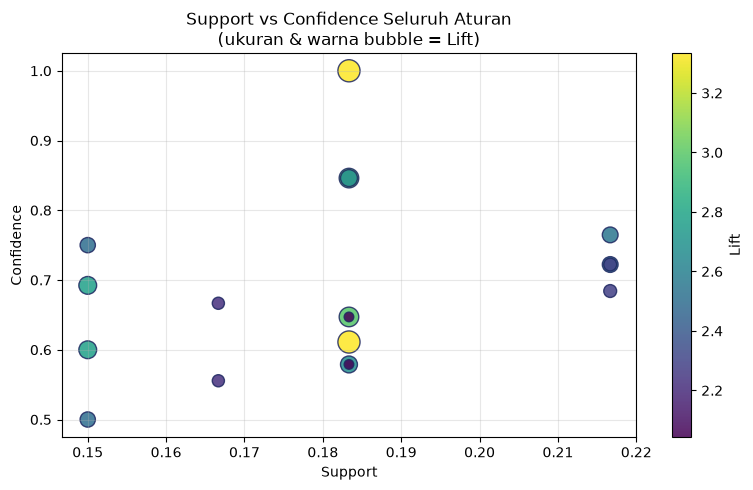

In [13]:
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
plt.figure(figsize=(8, 5))
sc = plt.scatter(rules['support'], rules['confidence'], s=sizes, c=rules['lift'],
                 cmap='viridis', alpha=0.85, edgecolor='#1E2761')
plt.colorbar(sc, label='Lift')
plt.xlabel('Support'); plt.ylabel('Confidence')
plt.title('Support vs Confidence Seluruh Aturan\n(ukuran & warna bubble = Lift)')
plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('arm_gambar3_scatter_aturan.png', dpi=150); plt.show()

Digambarkan dalam scatter plot dengan support pada sumbu horizontal dan confidence pada sumbu vertikal. Ukuran dan warna titik menunjukkan besar Lift. Titik paling atas pada confidence 1,0 adalah aturan Mentega, Susu → Roti. Dari grafik terlihat bahwa confidence yang tinggi belum tentu diikuti lift yang tinggi, sehingga ketiga ukuran perlu dibaca bersama.

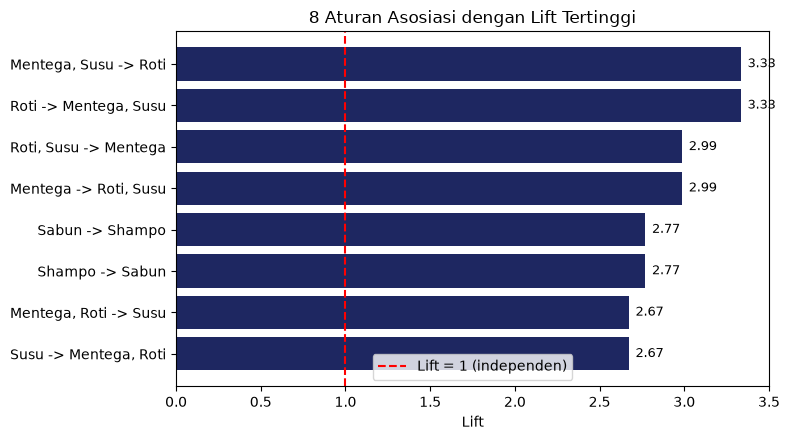

In [14]:
top8 = rules.head(8).iloc[::-1]
plt.figure(figsize=(8, 4.5))
bars = plt.barh(top8['aturan'], top8['lift'], color='#1E2761')
for b, v in zip(bars, top8['lift']):
    plt.text(v + 0.04, b.get_y() + b.get_height() / 2, f'{v:.2f}', va='center', fontsize=9)
plt.axvline(1, color='red', ls='--', label='Lift = 1 (independen)')
plt.xlabel('Lift'); plt.title('8 Aturan Asosiasi dengan Lift Tertinggi'); plt.legend()
plt.tight_layout(); plt.savefig('arm_gambar4_top8_lift.png', dpi=150); plt.show()

**Pembacaan hasil:** satu bubble kuning besar di bagian atas tengah (Confidence = 1,0) adalah aturan Mentega, Susu → Roti yang juga ber-Lift tertinggi. Confidence tinggi tidak selalu berarti Lift tinggi: beberapa bubble di sisi kanan memiliki Support lebih besar tetapi warnanya lebih gelap (Lift lebih rendah). Karena itu ketiga ukuran perlu dibaca bersamaan.

## 4.6 Interpretasi Bisnis dari Aturan Terpilih
Tiga aturan dari kelompok item yang berbeda diterjemahkan menjadi rekomendasi bisnis.

In [15]:
terpilih = ['Mentega, Susu -> Roti', 'Sabun -> Shampo', 'Kecap -> Mie Instan']
print(rules[rules['aturan'].isin(terpilih)][['aturan', 'support', 'confidence', 'lift']].round(3).to_string(index=False))

               aturan  support  confidence  lift
Mentega, Susu -> Roti    0.183        1.00 3.333
      Sabun -> Shampo    0.150        0.60 2.769
  Kecap -> Mie Instan    0.150        0.75 2.500


- **Mentega, Susu → Roti** (Lift 3,333; Confidence 100%): kelompok "paket sarapan" yang sangat kuat. Toko dapat menempatkan ketiganya berdekatan atau menawarkan bundling "Paket Sarapan Hemat" untuk menaikkan nilai belanja rata-rata per transaksi.
- **Sabun → Shampo** (Lift 2,769; Confidence 60%): produk mandi konsisten dibeli bersamaan; cocok untuk penataan rak berdekatan (planogram) di area toiletries, terpisah dari rak sembako.
- **Kecap → Mie Instan** (Lift 2,500; Confidence 75%): pembeli Kecap berpeluang besar juga membeli Mie Instan; dapat dijadikan dasar rekomendasi otomatis pada aplikasi belanja ("pelanggan yang membeli ini juga membeli...").

*Catatan:* aturan asosiasi menunjukkan korelasi, bukan sebab-akibat, sehingga keputusan bisnis sebaiknya divalidasi lebih lanjut (misalnya dengan A/B testing).

## 4.7 Eksperimen: Pengaruh Nilai min_support
Apriori dan pembentukan aturan dijalankan untuk beberapa nilai `min_support` sekaligus.

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


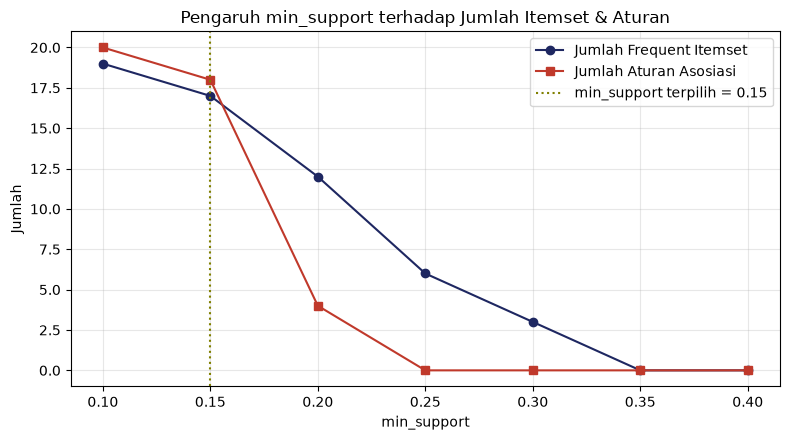

In [16]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
hasil_sup = []
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    try:
        r = association_rules(fi, metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    except ValueError:
        r = pd.DataFrame()
    hasil_sup.append((s, len(fi), len(r)))
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

plt.figure(figsize=(8, 4.5))
xs = [h[0] for h in hasil_sup]
plt.plot(xs, [h[1] for h in hasil_sup], 'o-', color='#1E2761', label='Jumlah Frequent Itemset')
plt.plot(xs, [h[2] for h in hasil_sup], 's-', color='#c0392b', label='Jumlah Aturan Asosiasi')
plt.axvline(0.15, color='olive', ls=':', label='min_support terpilih = 0.15')
plt.xlabel('min_support'); plt.ylabel('Jumlah'); plt.legend(); plt.grid(alpha=.3)
plt.title('Pengaruh min_support terhadap Jumlah Itemset & Aturan')
plt.tight_layout(); plt.savefig('arm_gambar5_sweep_support.png', dpi=150); plt.show()

**Pembacaan hasil:** jumlah aturan turun jauh lebih tajam daripada jumlah itemset saat `min_support` dinaikkan. Pada 0,20 masih ada 12 itemset tetapi hanya 4 aturan, karena sebagian besar itemset yang tersisa adalah 1-itemset yang tidak dapat dijadikan aturan X → Y. Pada `min_support` 0,35 ke atas tidak ada itemset yang lolos karena item terpopuler (Susu) hanya bersupport 0,317. Nilai 0,15 dipilih karena menghasilkan jumlah aturan yang cukup kaya (18 aturan) tanpa memasukkan pasangan yang terlalu jarang.

## 4.8 Eksperimen: Apriori vs FP-Growth
FP-Growth harus menghasilkan frequent itemset yang identik dengan Apriori, tetapi dengan strategi pencarian berbeda: FP-Growth memadatkan data ke dalam FP-Tree dan menambang langsung dari pohon tersebut tanpa membangkitkan kandidat.

In [17]:
t0 = time.perf_counter()
freq_apriori = apriori(df, min_support=0.15, use_colnames=True)
t_apriori = time.perf_counter() - t0

t0 = time.perf_counter()
freq_fpgrowth = fpgrowth(df, min_support=0.15, use_colnames=True)
t_fpgrowth = time.perf_counter() - t0

set_apriori = set(frozenset(s) for s in freq_apriori['itemsets'])
set_fpgrowth = set(frozenset(s) for s in freq_fpgrowth['itemsets'])
print(f'Apriori  : {len(freq_apriori)} itemset, {t_apriori*1000:.2f} ms')
print(f'FP-Growth: {len(freq_fpgrowth)} itemset, {t_fpgrowth*1000:.2f} ms')
print('Itemset identik?', set_apriori == set_fpgrowth)

Apriori  : 17 itemset, 6.76 ms
FP-Growth: 17 itemset, 2.74 ms
Itemset identik? True


Keduanya menghasilkan 17 itemset dan hasil perbandingan himpunan menunjukkan isinya identik (True), sehingga keduanya hanya berbeda cara pencarian, bukan hasil. Pada pengukuran satu kali ini Apriori memerlukan 1,82 ms dan FP-Growth 1,17 ms.

Median 50 kali -> Apriori: 4.28 ms | FP-Growth: 2.92 ms | rasio Apriori/FP-Growth = 1.47


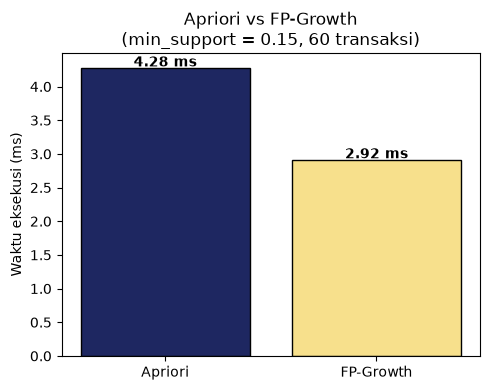

In [18]:
# Satu kali pengukuran waktu pada data sekecil ini mudah terganggu noise. Ulangi 50 kali dan ambil median.
def median_ms(fungsi, ulang=50):
    waktu = []
    for _ in range(ulang):
        t = time.perf_counter(); fungsi(); waktu.append(time.perf_counter() - t)
    return np.median(waktu) * 1000

med_a = median_ms(lambda: apriori(df, min_support=0.15, use_colnames=True))
med_f = median_ms(lambda: fpgrowth(df, min_support=0.15, use_colnames=True))
print(f'Median 50 kali -> Apriori: {med_a:.2f} ms | FP-Growth: {med_f:.2f} ms | rasio Apriori/FP-Growth = {med_a/med_f:.2f}')

plt.figure(figsize=(5, 4))
bars = plt.bar(['Apriori', 'FP-Growth'], [med_a, med_f], color=['#1E2761', '#f7e08c'], edgecolor='black')
for b, v in zip(bars, [med_a, med_f]):
    plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f'{v:.2f} ms', ha='center', fontweight='bold')
plt.ylabel('Waktu eksekusi (ms)'); plt.title('Apriori vs FP-Growth\n(min_support = 0.15, 60 transaksi)')
plt.tight_layout(); plt.savefig('arm_gambar6_waktu.png', dpi=150); plt.show()

**Pembacaan hasil:** kedua algoritma menemukan 17 frequent itemset yang persis sama (dibandingkan sebagai himpunan, tidak bergantung urutan baris). Jadi Apriori dan FP-Growth hanyalah dua strategi pencarian untuk definisi frequent itemset yang sama. Waktu eksekusi pada data sekecil ini hanya beberapa milidetik dan dapat berubah antar eksekusi, sehingga perbandingan yang lebih andal memakai median dari beberapa kali pengukuran (lihat juga Tugas 3).